# Agentic Reasoning for Data Science: Full Study (rerun with the fixed Reviewer)
End-to-end run of the cyclic LangGraph pipeline (Planner, EDA Analyst, ML Architect, Quality Reviewer, Report Writer) on three datasets, compared with a single agent and AutoGluon, on clean and corrupted data.

**What is different from the first version**
- Every system gets the same split, features and models. Corruption is seeded and applied to training data only.
- Results are reported on the training set **and** the held-out test set, so overfitting is visible.
- **F1 is reported everywhere**, next to MCC and balanced accuracy, plus an always-positive baseline. F1 alone is unsafe because predicting "positive" for everyone already scores a high F1 on these datasets. Models are chosen by cross-validated MCC on training data only.
- The Reviewer was rebuilt. It drops impossible values, flags leaked features (including a score-jump check) and only removes suspected wrong labels when a leak-free cross-validation test proves it helps. Otherwise it reports them.
- All tables and charts are built from the saved CSV files.

## Step 1: Setup and configuration

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import agentic_bench as ab, agentic_viz as viz

# ---- edit these paths ----
HEART_CSV  = os.path.expanduser("~/Downloads/archive/heart_disease_cleveland.csv")
NYC_PARQUET = os.path.expanduser("~/Downloads/yellow_tripdata_2024-01.parquet")
AMAZON_CSV = "data/amazon_beauty_50k.csv"     # columns: rating,text,verified,title,helpful_vote

# ---- run size ----
SEEDS = {"Heart_Disease": range(10), "Amazon_Reviews": range(5), "NYC_Taxi": range(5)}
USE_AUTOGLUON = False      # True adds AutoGluon (60 s per fit, slow)
USE_LLM = False            # True needs `ollama serve` and llama3.2; writes the plan and report text
QUICK = os.environ.get("QUICK") == "1"     # tiny run to check everything works
if QUICK:
    SEEDS = {k: range(2) for k in SEEDS}
os.makedirs("outputs", exist_ok=True)

llm = None
if USE_LLM:
    from langchain_ollama import OllamaLLM
    llm = OllamaLLM(model="llama3.2")
    print("Ollama connected")

## Step 2: Load the three datasets

In [2]:
%pip install vaderSentiment pyarrow shap seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
df_heart, t_heart = ab.load_heart(HEART_CSV)

def load_amazon_csv(path, n=5000, seed=42):
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    d = pd.read_csv(path).dropna(subset=["text", "title", "rating"])
    d = d[(d.text.str.len() > 0)].sample(n=min(n, len(d)), random_state=seed).reset_index(drop=True)
    sia = SentimentIntensityAnalyzer()
    out = pd.DataFrame({
        "text_length": d.text.str.len(), "title_length": d.title.astype(str).str.len(),
        "word_count": d.text.str.split().str.len(), "exclaim_count": d.text.str.count("!"),
        "upper_ratio": d.text.apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1)),
        "vader_text": d.text.apply(lambda s: sia.polarity_scores(s)["compound"]),
        "vader_title": d.title.astype(str).apply(lambda s: sia.polarity_scores(s)["compound"]),
        "helpful_vote": d.helpful_vote, "verified": d.verified.astype(int),
        "sentiment": (d.rating >= 4).astype(int)})
    return out, "sentiment"

df_nyc, t_nyc = ab.load_nyc(NYC_PARQUET, n=2000 if QUICK else 5000)
df_amz, t_amz = load_amazon_csv(AMAZON_CSV, n=1500 if QUICK else 5000)
DATA = {"Heart_Disease": (df_heart, t_heart), "NYC_Taxi": (df_nyc, t_nyc), "Amazon_Reviews": (df_amz, t_amz)}
for k, (d, t) in DATA.items():
    print(f"{k}: {d.shape}, positive rate {d[t].mean():.2f}, missing cells {int(d.isna().sum().sum())}")

Heart_Disease: (303, 14), positive rate 0.46, missing cells 6
NYC_Taxi: (5000, 8), positive rate 0.80, missing cells 0
Amazon_Reviews: (5000, 10), positive rate 0.74, missing cells 0


## Step 3: Exploratory data analysis

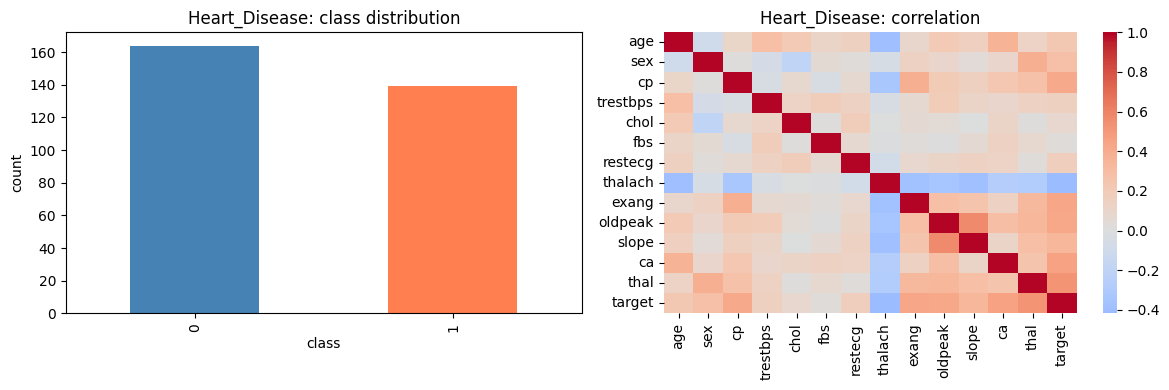

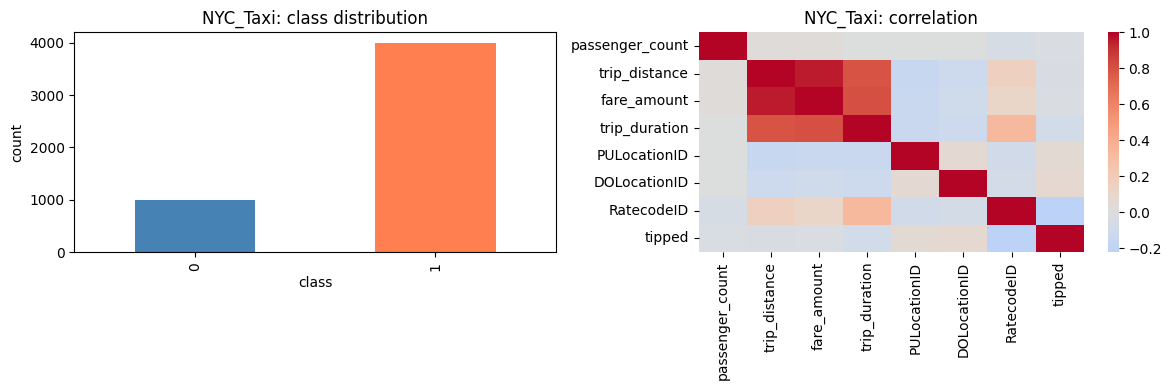

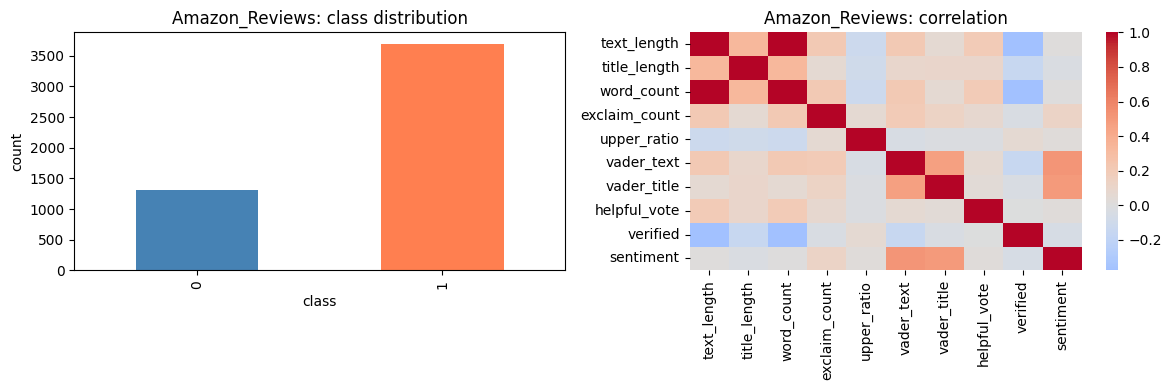

In [4]:
for k, (d, t) in DATA.items():
    viz.eda_plot(d, t, k)

## Step 4: One end-to-end graph run per dataset (with the fixed Reviewer)
This is the walkthrough: every node runs once, the Reviewer's decisions are printed, and SHAP shows what the final model uses. Train and test scores are shown side by side.

Heart_Disease: model=logreg bal_acc=0.847 mcc=0.704 auc=0.922 retries=1
planner: Heart_Disease: 242 train rows, risks: ['missing values']
ml: default/logreg thr=0.50 bal_acc=0.865 mcc=0.736
reviewer: 36 rows look mislabeled but dropping them did not clearly help (CV gain +0.032), reported only
reviewer: 12 impossible values -> retry_eda
eda: dropped 12 rows with impossible values
ml: default/logreg thr=0.50 bal_acc=0.847 mcc=0.704
reviewer: all checks passed
              train   test
f1            0.715  0.830
mcc           0.452  0.704
balanced_acc  0.726  0.847
recall        0.699  0.786
specificity   0.752  0.909
auc           0.817  0.922


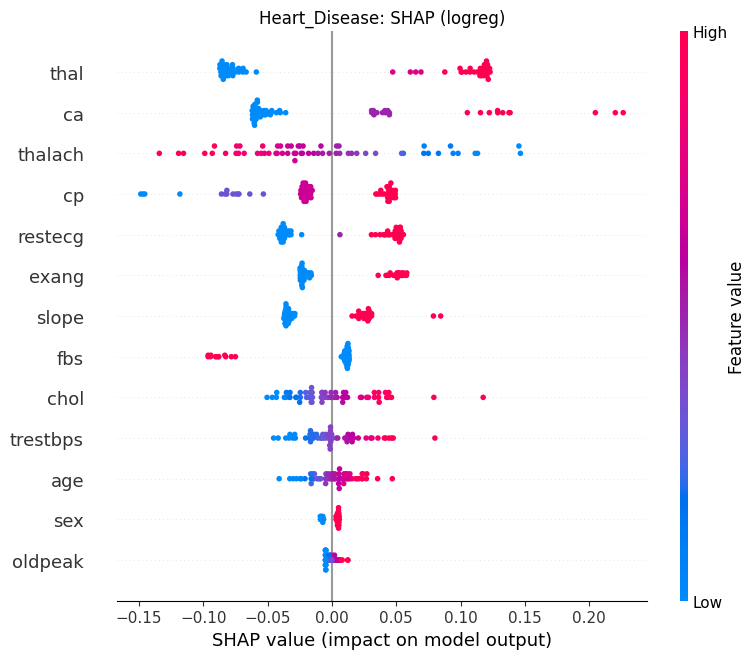

NYC_Taxi: model=logreg bal_acc=0.535 mcc=0.238 auc=0.595 retries=1
planner: NYC_Taxi: 4000 train rows, risks: ['imbalance (minority 29%)']
ml: default/logreg thr=0.50 bal_acc=0.535 mcc=0.238
reviewer: 71 rows look mislabeled but dropping them did not clearly help (CV gain +0.008), reported only
reviewer: 200 impossible values -> retry_eda
eda: dropped 200 rows with impossible values
ml: default/logreg thr=0.50 bal_acc=0.535 mcc=0.238
reviewer: retry changed nothing, stopping
              train   test
f1            0.832  0.896
mcc           0.143  0.238
balanced_acc  0.517  0.535
recall        0.998  1.000
specificity   0.036  0.070
auc           0.543  0.595


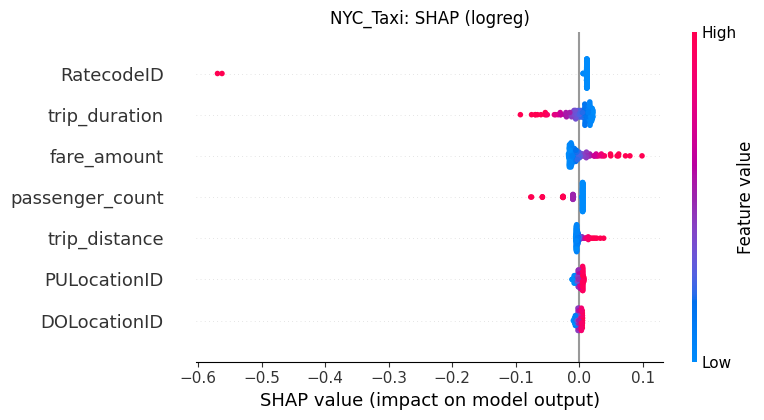

Amazon_Reviews: model=logreg bal_acc=0.762 mcc=0.559 auc=0.874 retries=1
planner: Amazon_Reviews: 4000 train rows, risks: ['imbalance (minority 33%)']
ml: default/rf thr=0.50 bal_acc=0.772 mcc=0.553
reviewer: 599 rows look mislabeled but dropping them did not clearly help (CV gain +0.014), reported only
reviewer: 200 impossible values -> retry_eda
eda: dropped 200 rows with impossible values
ml: default/logreg thr=0.50 bal_acc=0.762 mcc=0.559
reviewer: all checks passed
              train   test
f1            0.818  0.894
mcc           0.361  0.559
balanced_acc  0.656  0.762
recall        0.894  0.922
specificity   0.418  0.602
auc           0.739  0.874


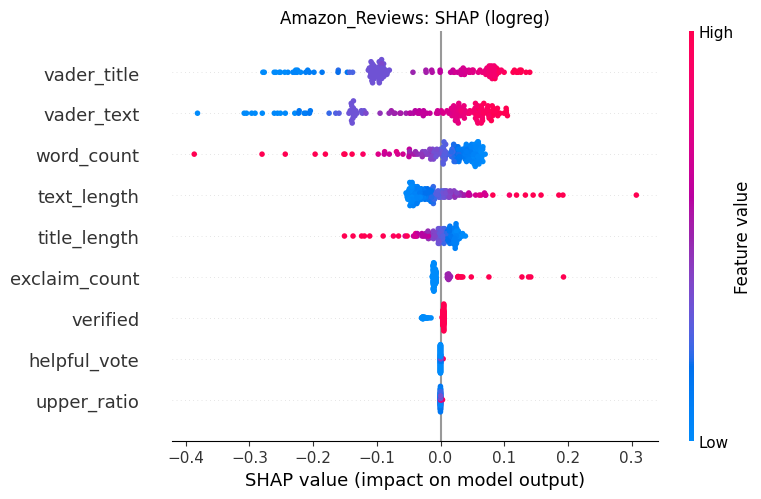

In [5]:
demo = {}
for k, (d, t) in DATA.items():
    d2 = ab.add_rid(d)
    train, test = ab.make_split(d2, t, seed=0)
    tr_c, info = ab.corrupt_train(train, t, k, label_noise=0.15, imp_rate=0.05, seed=0)
    app = ab.build_graph(use_reviewer=True, llm=llm, reviewer_mode="fixed")
    out = ab.run_graph(app, tr_c, test, t, k)
    demo[k] = out
    print("=" * 70); print(out["final_report"])
    tr_m, te_m = out["train_metrics"], out["metrics"]
    print(pd.DataFrame({"train": tr_m, "test": te_m}).loc[["f1", "mcc", "balanced_acc", "recall", "specificity", "auc"]].round(3))
    viz.shap_plot(out, k)

## Step 5: Full benchmark on clean and corrupted data
Conditions are (label noise, impossible-value rate): (0, 0), (5%, 2%), (15%, 5%), (30%, 5%). Systems: always positive, single agent, graph without reviewer, graph with the old reviewer, graph with the fixed reviewer, and optionally AutoGluon.

In [7]:
ab.cv_gain_from_dropping.__defaults__ = ((0,),)

In [8]:
SEEDS = {"Heart_Disease": range(10), "Amazon_Reviews": range(3), "NYC_Taxi": range(3)}

In [9]:
import time
frames = [pd.read_csv("outputs/full_Heart_Disease.csv")]
for k in ["NYC_Taxi", "Amazon_Reviews"]:
    t0 = time.time()
    r = ab.run_experiment({k: DATA[k]}, seeds=SEEDS[k], use_autogluon=USE_AUTOGLUON, llm=llm,
                          out_csv=f"outputs/full_{k}.csv", verbose=True)
    frames.append(r)
    print(k, "done in", round((time.time() - t0) / 60, 1), "min")
res = pd.concat(frames, ignore_index=True)
res.to_csv("outputs/full_all.csv", index=False)
print(res.shape)

NYC_Taxi seed=0 label_noise=0.0 imp_rate=0.0
NYC_Taxi seed=0 label_noise=0.05 imp_rate=0.02
NYC_Taxi seed=0 label_noise=0.15 imp_rate=0.05
NYC_Taxi seed=0 label_noise=0.3 imp_rate=0.05
NYC_Taxi seed=1 label_noise=0.0 imp_rate=0.0
NYC_Taxi seed=1 label_noise=0.05 imp_rate=0.02
NYC_Taxi seed=1 label_noise=0.15 imp_rate=0.05
NYC_Taxi seed=1 label_noise=0.3 imp_rate=0.05
NYC_Taxi seed=2 label_noise=0.0 imp_rate=0.0
NYC_Taxi seed=2 label_noise=0.05 imp_rate=0.02
NYC_Taxi seed=2 label_noise=0.15 imp_rate=0.05
NYC_Taxi seed=2 label_noise=0.3 imp_rate=0.05
NYC_Taxi done in 8.0 min
Amazon_Reviews seed=0 label_noise=0.0 imp_rate=0.0
Amazon_Reviews seed=0 label_noise=0.05 imp_rate=0.02
Amazon_Reviews seed=0 label_noise=0.15 imp_rate=0.05
Amazon_Reviews seed=0 label_noise=0.3 imp_rate=0.05
Amazon_Reviews seed=1 label_noise=0.0 imp_rate=0.0
Amazon_Reviews seed=1 label_noise=0.05 imp_rate=0.02
Amazon_Reviews seed=1 label_noise=0.15 imp_rate=0.05
Amazon_Reviews seed=1 label_noise=0.3 imp_rate=0.05
Am

## Step 6: Results tables (test set, mean ± standard deviation over seeds)

In [10]:
for k in DATA:
    print(f"\n===== {k} =====")
    display(viz.summary_table(res, k))


===== Heart_Disease =====


f1            mcc   balanced_acc  \
label_noise system                                                              
0.00        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.797 ± 0.049  0.646 ± 0.084  0.818 ± 0.041   
            graph_no_reviewer     0.797 ± 0.049  0.646 ± 0.084  0.818 ± 0.041   
            graph_reviewer_v1     0.793 ± 0.063  0.638 ± 0.106  0.814 ± 0.053   
            graph_reviewer_fixed  0.799 ± 0.043   0.65 ± 0.076   0.82 ± 0.037   
0.05        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.801 ± 0.059  0.654 ± 0.102  0.822 ± 0.051   
            graph_no_reviewer     0.801 ± 0.059  0.654 ± 0.102  0.822 ± 0.051   
            graph_reviewer_v1      0.79 ± 0.041  0.632 ± 0.073  0.811 ± 0.035   
            graph_reviewer_fixed  0.799 ± 0.058    0.654 ± 0.1  0.821 ± 0.049   
0.15        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.798 ± 0.058  0.651 ± 0.106  0.819 ± 0.052   
            graph_no_reviewer     0.798 ± 0.058  0.651 ± 0.106  0.819 ± 0.052   
            graph_reviewer_v1     0.756 ± 0.065  0.562 ± 0.133  0.777 ± 0.064   
            graph_reviewer_fixed  0.787 ± 0.057  0.628 ± 0.093  0.809 ± 0.047   
0.30        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.723 ± 0.063  0.504 ± 0.102  0.749 ± 0.052   
            graph_no_reviewer     0.723 ± 0.063  0.504 ± 0.102  0.749 ± 0.052   
            graph_reviewer_v1     0.702 ± 0.089  0.443 ± 0.199  0.717 ± 0.097   
            graph_reviewer_fixed   0.71 ± 0.067  0.466 ± 0.128  0.731 ± 0.063   

                                         recall    specificity            auc  
label_noise system                                                             
0.00        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent          0.757 ± 0.065  0.879 ± 0.057  0.896 ± 0.036  
            graph_no_reviewer     0.757 ± 0.065  0.879 ± 0.057  0.896 ± 0.036  
            graph_reviewer_v1     0.761 ± 0.086  0.867 ± 0.085   0.891 ± 0.04  
            graph_reviewer_fixed  0.761 ± 0.058  0.879 ± 0.057  0.896 ± 0.037  
0.05        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent          0.764 ± 0.085   0.879 ± 0.07   0.898 ± 0.04  
            graph_no_reviewer     0.764 ± 0.085   0.879 ± 0.07   0.898 ± 0.04  
            graph_reviewer_v1     0.761 ± 0.072  0.861 ± 0.073  0.891 ± 0.035  
            graph_reviewer_fixed  0.754 ± 0.072  0.888 ± 0.066    0.9 ± 0.042  
0.15        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent          0.757 ± 0.073  0.882 ± 0.078  0.878 ± 0.047  
            graph_no_reviewer     0.757 ± 0.073  0.882 ± 0.078  0.878 ± 0.047  
            graph_reviewer_v1     0.739 ± 0.072  0.815 ± 0.098  0.864 ± 0.046  
            graph_reviewer_fixed  0.757 ± 0.089  0.861 ± 0.072   0.87 ± 0.049  
0.30        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent          0.707 ± 0.086  0.791 ± 0.081  0.817 ± 0.071  
            graph_no_reviewer     0.707 ± 0.086  0.791 ± 0.081  0.817 ± 0.071  
            graph_reviewer_v1     0.711 ± 0.085  0.724 ± 0.168  0.805 ± 0.082  
            graph_reviewer_fixed  0.711 ± 0.076  0.752 ± 0.099  0.798 ± 0.081


===== NYC_Taxi =====


f1            mcc   balanced_acc  \
label_noise system                                                              
0.00        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.894 ± 0.002  0.202 ± 0.053  0.527 ± 0.013   
            graph_no_reviewer     0.894 ± 0.002  0.202 ± 0.053  0.527 ± 0.013   
            graph_reviewer_v1     0.841 ± 0.091  0.172 ± 0.047   0.546 ± 0.04   
            graph_reviewer_fixed  0.806 ± 0.019  0.129 ± 0.034   0.569 ± 0.02   
0.05        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013   
            graph_no_reviewer     0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013   
            graph_reviewer_v1      0.86 ± 0.059  0.156 ± 0.076  0.532 ± 0.018   
            graph_reviewer_fixed   0.86 ± 0.059  0.156 ± 0.076  0.532 ± 0.018   
0.15        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013   
            graph_no_reviewer     0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013   
            graph_reviewer_v1      0.84 ± 0.093  0.157 ± 0.074  0.534 ± 0.022   
            graph_reviewer_fixed   0.84 ± 0.093  0.157 ± 0.074  0.534 ± 0.022   
0.30        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013   
            graph_no_reviewer     0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013   
            graph_reviewer_v1      0.78 ± 0.106   0.13 ± 0.094  0.542 ± 0.007   
            graph_reviewer_fixed   0.78 ± 0.106   0.13 ± 0.094  0.542 ± 0.007   

                                         recall    specificity            auc  
label_noise system                                                             
0.00        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent            1.0 ± 0.001  0.055 ± 0.026  0.586 ± 0.018  
            graph_no_reviewer       1.0 ± 0.001  0.055 ± 0.026  0.586 ± 0.018  
            graph_reviewer_v1     0.883 ± 0.201  0.208 ± 0.279  0.595 ± 0.017  
            graph_reviewer_fixed  0.785 ± 0.039  0.353 ± 0.063  0.596 ± 0.024  
0.05        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent              1.0 ± 0.0  0.055 ± 0.026  0.567 ± 0.007  
            graph_no_reviewer         1.0 ± 0.0  0.055 ± 0.026  0.567 ± 0.007  
            graph_reviewer_v1     0.922 ± 0.136  0.142 ± 0.165  0.587 ± 0.012  
            graph_reviewer_fixed  0.922 ± 0.136  0.142 ± 0.165  0.587 ± 0.012  
0.15        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent              1.0 ± 0.0  0.055 ± 0.026  0.574 ± 0.013  
            graph_no_reviewer         1.0 ± 0.0  0.055 ± 0.026  0.574 ± 0.013  
            graph_reviewer_v1     0.885 ± 0.198  0.183 ± 0.236   0.587 ± 0.01  
            graph_reviewer_fixed  0.885 ± 0.198  0.183 ± 0.236   0.587 ± 0.01  
0.30        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent              1.0 ± 0.0  0.055 ± 0.026  0.578 ± 0.023  
            graph_no_reviewer         1.0 ± 0.0  0.055 ± 0.026  0.578 ± 0.023  
            graph_reviewer_v1     0.764 ± 0.212   0.32 ± 0.226  0.571 ± 0.031  
            graph_reviewer_fixed  0.764 ± 0.212   0.32 ± 0.226  0.571 ± 0.031


===== Amazon_Reviews =====


f1            mcc   balanced_acc  \
label_noise system                                                              
0.00        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012   
            graph_no_reviewer     0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012   
            graph_reviewer_v1     0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012   
            graph_reviewer_fixed  0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012   
0.05        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.893 ± 0.004  0.574 ± 0.021   0.78 ± 0.014   
            graph_no_reviewer     0.893 ± 0.004  0.574 ± 0.021   0.78 ± 0.014   
            graph_reviewer_v1     0.895 ± 0.001  0.577 ± 0.005  0.778 ± 0.003   
            graph_reviewer_fixed  0.895 ± 0.001  0.577 ± 0.005  0.778 ± 0.003   
0.15        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.882 ± 0.007  0.545 ± 0.018  0.771 ± 0.006   
            graph_no_reviewer     0.882 ± 0.007  0.545 ± 0.018  0.771 ± 0.006   
            graph_reviewer_v1     0.886 ± 0.014  0.553 ± 0.035   0.77 ± 0.015   
            graph_reviewer_fixed  0.886 ± 0.014  0.553 ± 0.035   0.77 ± 0.015   
0.30        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0   
            single_agent          0.889 ± 0.004  0.532 ± 0.024  0.744 ± 0.017   
            graph_no_reviewer     0.889 ± 0.004  0.532 ± 0.024  0.744 ± 0.017   
            graph_reviewer_v1     0.889 ± 0.003  0.532 ± 0.026  0.743 ± 0.028   
            graph_reviewer_fixed  0.889 ± 0.003  0.532 ± 0.026  0.743 ± 0.028   

                                         recall    specificity            auc  
label_noise system                                                             
0.00        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent          0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007  
            graph_no_reviewer     0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007  
            graph_reviewer_v1     0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007  
            graph_reviewer_fixed  0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007  
0.05        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent          0.904 ± 0.005  0.655 ± 0.029  0.887 ± 0.012  
            graph_no_reviewer     0.904 ± 0.005  0.655 ± 0.029  0.887 ± 0.012  
            graph_reviewer_v1     0.912 ± 0.003  0.644 ± 0.007  0.884 ± 0.005  
            graph_reviewer_fixed  0.912 ± 0.003  0.644 ± 0.007  0.884 ± 0.005  
0.15        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent          0.884 ± 0.014  0.659 ± 0.007  0.862 ± 0.013  
            graph_no_reviewer     0.884 ± 0.014  0.659 ± 0.007  0.862 ± 0.013  
            graph_reviewer_v1      0.895 ± 0.03  0.645 ± 0.038  0.861 ± 0.013  
            graph_reviewer_fixed   0.895 ± 0.03  0.645 ± 0.038  0.861 ± 0.013  
0.30        always_positive           1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0  
            single_agent           0.923 ± 0.01  0.564 ± 0.041  0.863 ± 0.009  
            graph_no_reviewer      0.923 ± 0.01  0.564 ± 0.041  0.863 ± 0.009  
            graph_reviewer_v1     0.923 ± 0.022  0.563 ± 0.077  0.865 ± 0.006  
            graph_reviewer_fixed  0.923 ± 0.022  0.563 ± 0.077  0.865 ± 0.006

## Step 7: Charts

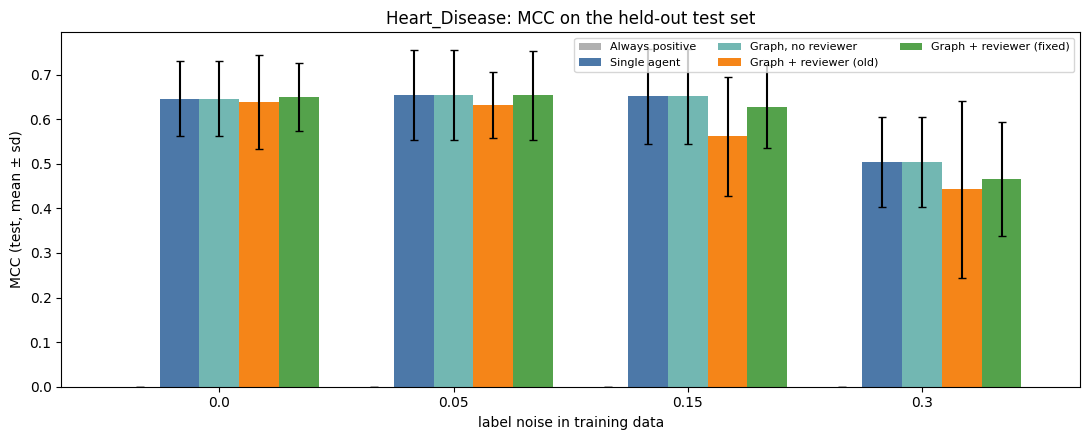

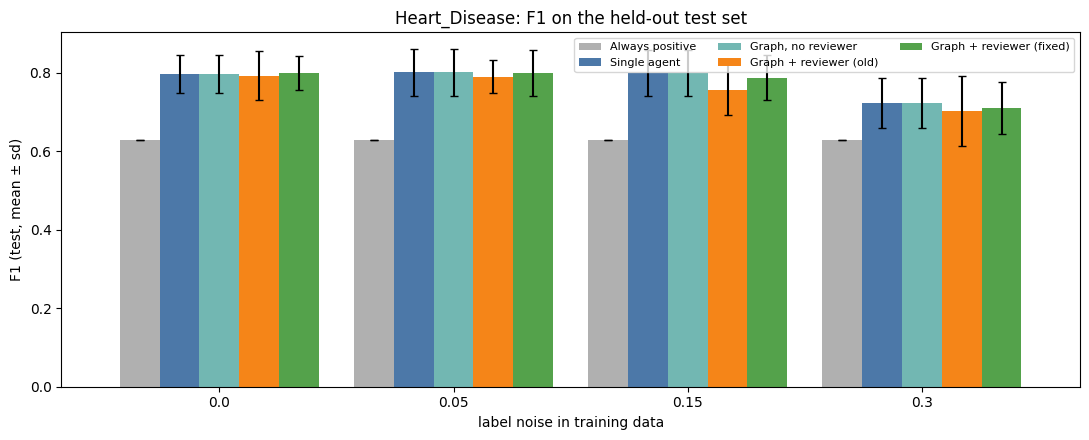

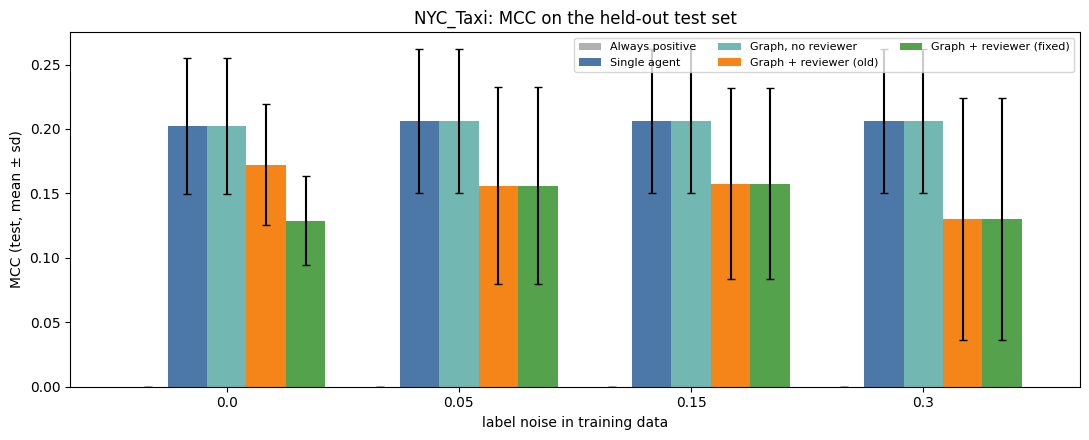

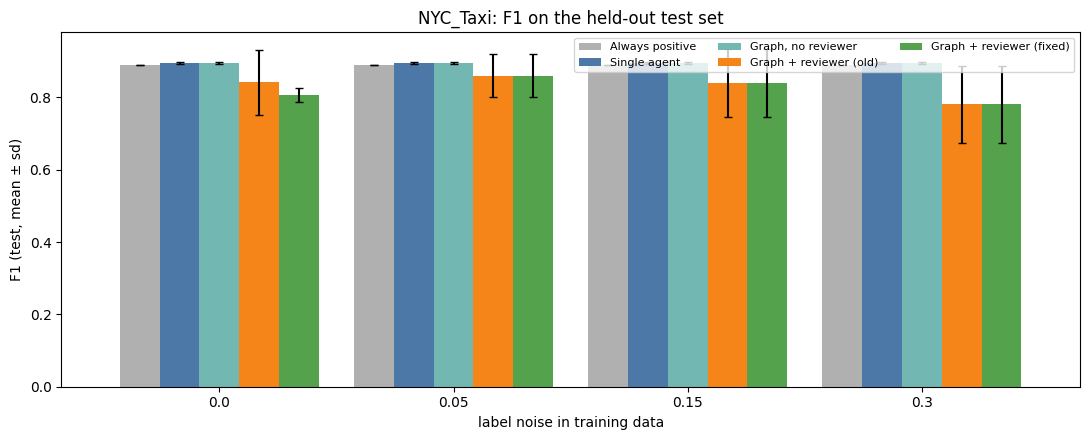

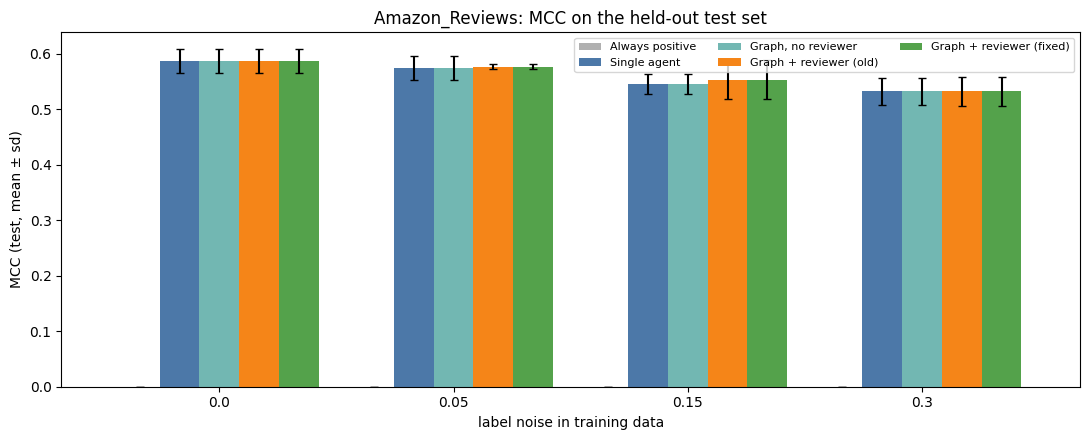

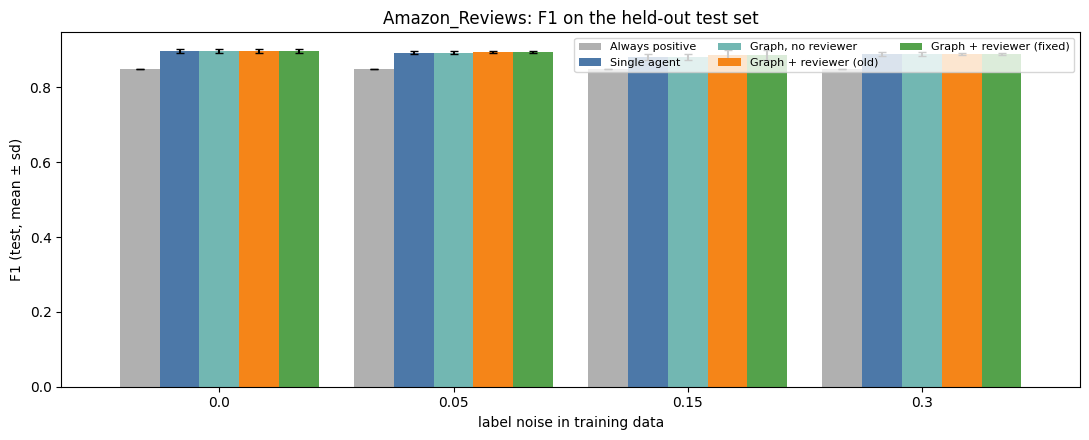

In [11]:
for k in DATA:
    viz.bar_by_condition(res, k, "mcc")
    viz.bar_by_condition(res, k, "f1", title=f"{k}: F1 on the held-out test set")

### F1 versus MCC: why F1 alone can mislead

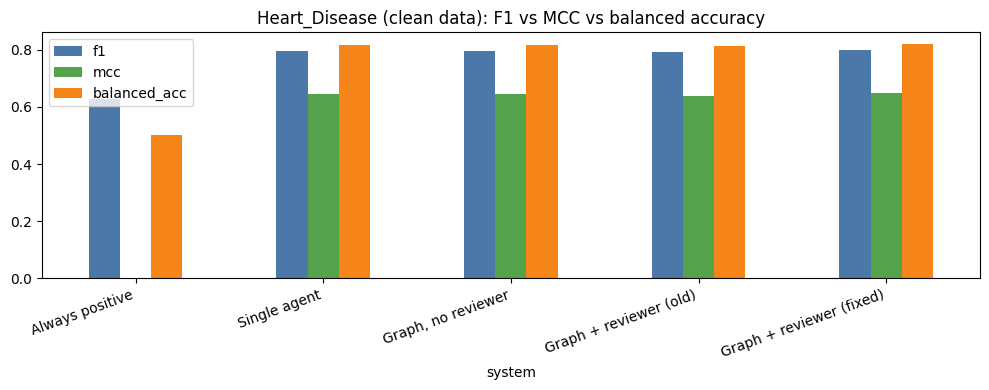

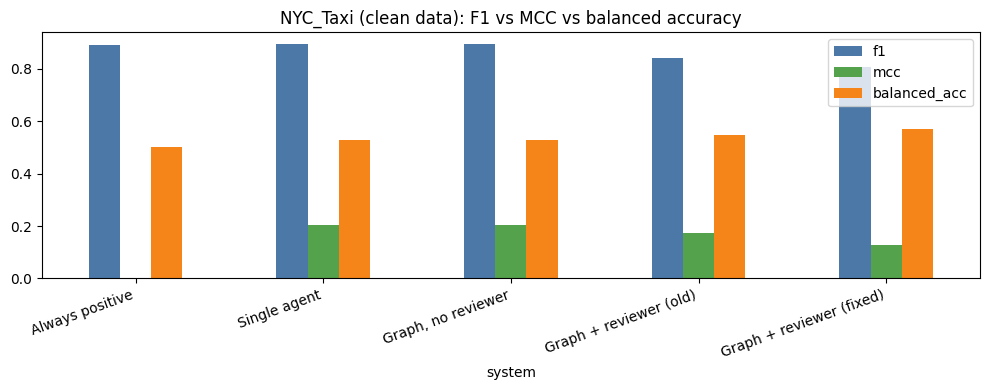

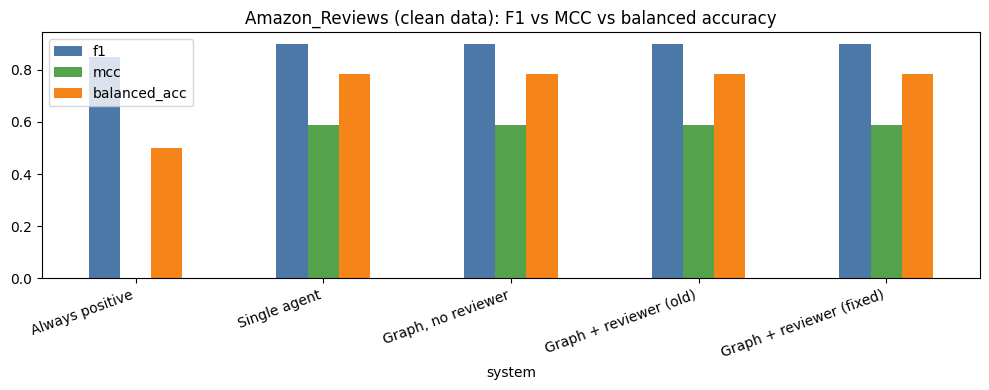

In [12]:
for k in DATA:
    viz.f1_vs_mcc(res, k)

### Train versus test (overfitting check)

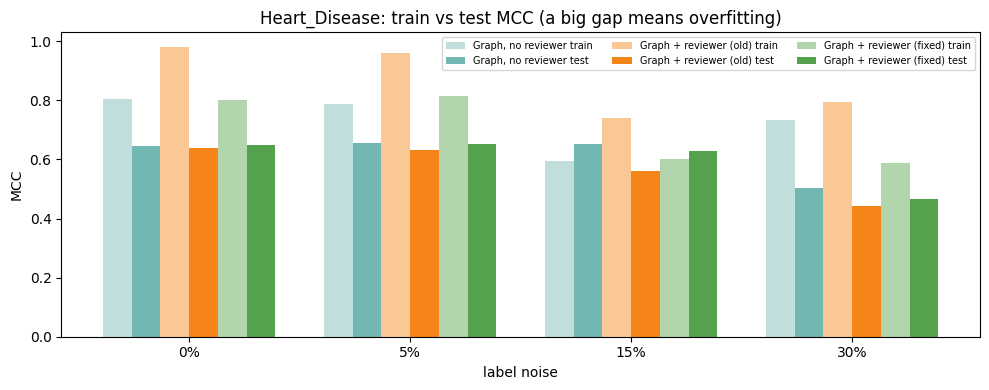

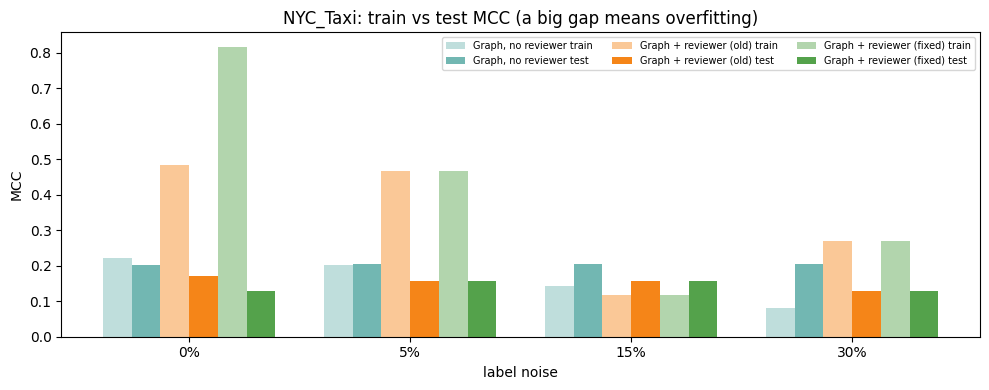

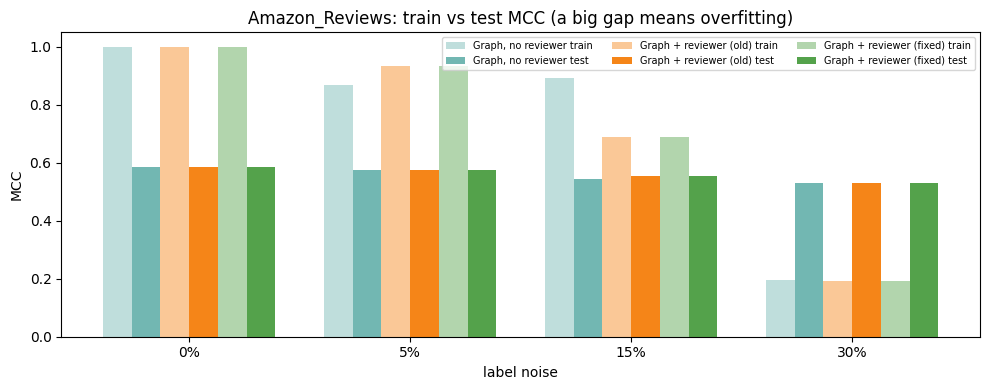

In [13]:
for k in DATA:
    viz.train_vs_test(res, k, "mcc")

### Did the Reviewer find the corrupted rows?

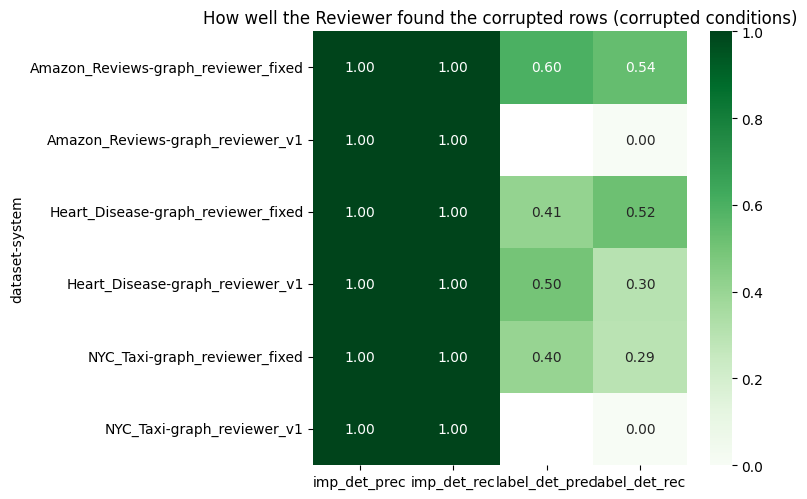

Rows the fixed Reviewer flagged but did not remove (mean per run):
                            n_flagged_label  n_dropped_label
dataset        label_noise                                  
Amazon_Reviews 0.00                   269.3              0.0
               0.05                   362.7              0.0
               0.15                   539.3              0.0
               0.30                   607.7              0.0
Heart_Disease  0.00                    28.5              0.0
               0.05                    34.9              0.0
               0.15                    45.5              0.0
               0.30                    48.6              0.0
NYC_Taxi       0.00                   616.0              0.0
               0.05                   432.3              0.0
               0.15                   388.7              0.0
               0.30                   373.0              0.0


In [14]:
viz.detection_heatmap(res)
print("Rows the fixed Reviewer flagged but did not remove (mean per run):")
print(res[res.system == "graph_reviewer_fixed"].groupby(["dataset", "label_noise"])[["n_flagged_label", "n_dropped_label"]].mean().round(1))

## Step 8: Leakage test
A near-copy of the label is added as a feature. A system that does not catch it scores close to 1.0 without any real skill. The honest score is about 0.65 on Heart Disease.

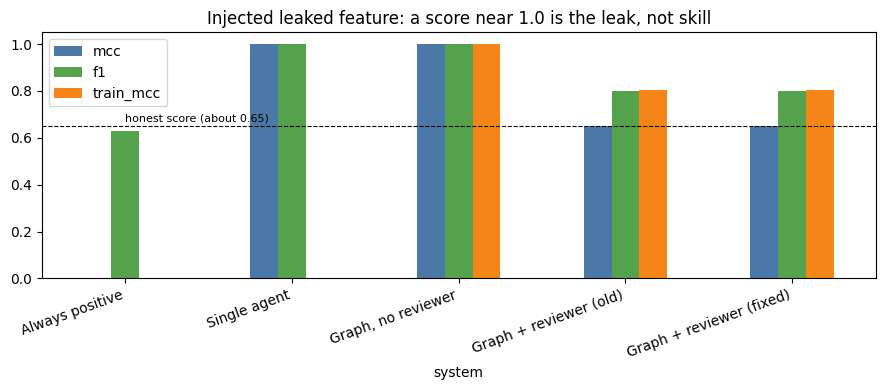

                       mcc     f1 leaky_flagged
system                                         
always_positive       0.00  0.629           NaN
graph_no_reviewer     1.00  1.000           0.0
graph_reviewer_fixed  0.65  0.799           1.0
graph_reviewer_v1     0.65  0.799           1.0
single_agent          1.00  1.000           NaN


In [15]:
leak = ab.run_experiment({"Heart_Disease": DATA["Heart_Disease"]}, seeds=SEEDS["Heart_Disease"], conditions=[(0.0, 0.0)],
                         leak=True, llm=llm, out_csv="outputs/full_leak.csv", verbose=False)
viz.leak_plot(leak)
print(leak.groupby("system")[["mcc", "f1", "leaky_flagged"]].mean().round(3))

## Step 9: Findings (computed from the results above)

In [16]:
m = res.groupby(["dataset", "label_noise", "system"])["mcc"].mean().unstack("system")
f = res.groupby(["dataset", "label_noise", "system"])["f1"].mean().unstack("system")
print("MCC, mean over seeds"); display(m.round(3))
print("F1, mean over seeds");  display(f.round(3))
d = (m["graph_reviewer_fixed"] - m["graph_no_reviewer"]).round(3)
print("\nFixed Reviewer minus no Reviewer (MCC):"); print(d.to_string())
print("\nLeak test, fixed reviewer flagged the leaky feature in", int(leak[leak.system == "graph_reviewer_fixed"].leaky_flagged.sum()),
      "of", int((leak.system == "graph_reviewer_fixed").sum()), "runs")

MCC, mean over seeds


system                      always_positive  graph_no_reviewer  \
dataset        label_noise                                       
Amazon_Reviews 0.00                     0.0              0.587   
               0.05                     0.0              0.574   
               0.15                     0.0              0.545   
               0.30                     0.0              0.532   
Heart_Disease  0.00                     0.0              0.646   
               0.05                     0.0              0.654   
               0.15                     0.0              0.651   
               0.30                     0.0              0.504   
NYC_Taxi       0.00                     0.0              0.202   
               0.05                     0.0              0.206   
               0.15                     0.0              0.206   
               0.30                     0.0              0.206   

system                      graph_reviewer_fixed  graph_reviewer_v1  \
dataset        label_noise                                            
Amazon_Reviews 0.00                        0.587              0.587   
               0.05                        0.577              0.577   
               0.15                        0.553              0.553   
               0.30                        0.532              0.532   
Heart_Disease  0.00                        0.650              0.638   
               0.05                        0.654              0.632   
               0.15                        0.628              0.562   
               0.30                        0.466              0.443   
NYC_Taxi       0.00                        0.129              0.172   
               0.05                        0.156              0.156   
               0.15                        0.157              0.157   
               0.30                        0.130              0.130   

system                      single_agent  
dataset        label_noise                
Amazon_Reviews 0.00                0.587  
               0.05                0.574  
               0.15                0.545  
               0.30                0.532  
Heart_Disease  0.00                0.646  
               0.05                0.654  
               0.15                0.651  
               0.30                0.504  
NYC_Taxi       0.00                0.202  
               0.05                0.206  
               0.15                0.206  
               0.30                0.206

F1, mean over seeds


system                      always_positive  graph_no_reviewer  \
dataset        label_noise                                       
Amazon_Reviews 0.00                   0.850              0.898   
               0.05                   0.850              0.893   
               0.15                   0.850              0.882   
               0.30                   0.850              0.889   
Heart_Disease  0.00                   0.629              0.797   
               0.05                   0.629              0.801   
               0.15                   0.629              0.798   
               0.30                   0.629              0.723   
NYC_Taxi       0.00                   0.889              0.894   
               0.05                   0.889              0.894   
               0.15                   0.889              0.894   
               0.30                   0.889              0.894   

system                      graph_reviewer_fixed  graph_reviewer_v1  \
dataset        label_noise                                            
Amazon_Reviews 0.00                        0.898              0.898   
               0.05                        0.895              0.895   
               0.15                        0.886              0.886   
               0.30                        0.889              0.889   
Heart_Disease  0.00                        0.799              0.793   
               0.05                        0.799              0.790   
               0.15                        0.787              0.756   
               0.30                        0.710              0.702   
NYC_Taxi       0.00                        0.806              0.841   
               0.05                        0.860              0.860   
               0.15                        0.840              0.840   
               0.30                        0.780              0.780   

system                      single_agent  
dataset        label_noise                
Amazon_Reviews 0.00                0.898  
               0.05                0.893  
               0.15                0.882  
               0.30                0.889  
Heart_Disease  0.00                0.797  
               0.05                0.801  
               0.15                0.798  
               0.30                0.723  
NYC_Taxi       0.00                0.894  
               0.05                0.894  
               0.15                0.894  
               0.30                0.894


Fixed Reviewer minus no Reviewer (MCC):
dataset         label_noise
Amazon_Reviews  0.00           0.000
                0.05           0.003
                0.15           0.008
                0.30          -0.000
Heart_Disease   0.00           0.003
                0.05          -0.001
                0.15          -0.023
                0.30          -0.038
NYC_Taxi        0.00          -0.073
                0.05          -0.050
                0.15          -0.049
                0.30          -0.076

Leak test, fixed reviewer flagged the leaky feature in 10 of 10 runs


### How to read the findings
- Compare MCC and balanced accuracy first. F1 is shown for continuity with the first version, but the always-positive row shows how high F1 can be without any skill.
- A Reviewer that matches the no-reviewer score on clean data and catches impossible values and leaks is doing its job. Do not claim it improves accuracy unless the table shows a gap larger than the standard deviation.
- Write the final conclusions from the numbers printed in this notebook, not from the earlier README.